# 阶段 2：建模与相变 —— 回答「方程是什么、相图怎么变」

> **阶段定位**：第 3–5 周｜过关产出 = 单振子 RK4 仿真程序 + 混沌态/大尺度周期态两幅并列相图 + x(t) 时序图 + 一张可复现参数表（[阅读路线](../00-总览/阅读路线.md) 阶段 2）。对应课题「主要内容 2」的三个动词：**建立模型 / 分析相轨迹演变 / 确定临界阈值**。
>
> **本号要回答的五个问题**（阅读路线阶段 2「带着问题读」）：
> 1. Holmes–Duffing 方程各项物理含义？
> 2. 阻尼 $k$、策动力 $\lambda$、内置频率 $\omega$ 各怎么取？
> 3. RK4 步长取多少才稳定？
> 4. $\lambda$ 从小到大时相轨迹如何从混沌跃到大尺度周期态？
> 5. 「变尺度」为什么能解决极低频？
>
> **边界**：本号做到「阈值带标定 + 变尺度原理与反例」为止。判态伪代码与初相位盲区属于阶段 3；$P_d/P_{fa}$、ROC、门限数值属于阶段 4；定点化属于阶段 5。
>
> **纪律**：经验阈值报**带**不报点；本复现检验的是论文 claim 的**敏感性与可复现性**，不是「证明论文错了」——求解器、步长、判据、噪声条件都不同。

In [1]:
# 环境、全局参数、绘图设置（与 learn/0.ipynb / 1.ipynb 同款）
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if ((q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file()):
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')
    print(f'[图] {path}')

# ---- 可复现参数表（★[2] Eq.2/3 + 本机复现条件）----
K        = 0.5      # 阻尼 k（论文给定）
OMEGA    = 1.0      # 内驱角频率（rad/s）；极低频靠变尺度折到这里
LAM0     = 0.72     # 论文预置工作点（经验值，本号重新标定）
C_TRIG   = 0.73     # 论文声称的触发合成幅值（经验值）
H        = 0.02     # RK4 步长（s）；论文用 Simulink Ode4 / h=0.1
T        = 400.0    # 总仿真时长（s）
BURN     = 200.0    # 丢弃瞬态（s）
T_FAST   = 200.0    # 批量扫描短时长
BURN_FAST= 100.0
PSTD_TH  = 0.08     # Poincaré 离散度判态阈值（本机条件）
_START = time.time()

print(f'ROOT = {ROOT}')
print(f'k={K}, ω={OMEGA} rad/s, λ0={LAM0}, h={H}s, T={T}s, burn={BURN}s, pstd阈值={PSTD_TH}')

ROOT = C:\Users\22902\WorkBuddy\毕设
k=0.5, ω=1.0 rad/s, λ0=0.72, h=0.02s, T=400.0s, burn=200.0s, pstd阈值=0.08


## 1｜问 1：方程各项的物理含义

标准 Holmes–Duffing 是 $\ddot x+k\dot x-x+x^3=\lambda\cos\omega t$。母本 ★[2] 把线性恢复力换成五次项（Eq.2/3）：

$$\ddot x+0.5\dot x-x^3+x^5=\underbrace{\lambda\cos(t+\beta)}_{\text{内置参考}}+\underbrace{\gamma\cos(t+\theta)}_{\text{待测信号}}+n(t)$$

写成一阶系统令 $y=\dot x$：$\dot x=y,\ \dot y=-0.5y+x^3-x^5+u(t)$。恢复力 $F(x)=x^3-x^5=-V'(x)$ 来自双阱势

$$V(x)=-\frac{x^4}{4}+\frac{x^6}{6}$$

| 项 | 作用 | 取值 / 出处 |
|---|---|---|
| $\ddot x$ | 惯性 | 状态 $x$ 位移、$y$ 速度，二阶拆两个一阶才能积分 |
| $0.5\dot x$ | 阻尼（耗散） | $k=0.5$【★[2] Eq.2】；没有它系统不收敛到吸引子 |
| $-x^3+x^5$ | 改进恢复力 | 双阱、阱壁比标准 Duffing 更陡【★[2]】；势阱底在 $x=\pm1$，$V(\pm1)=-1/12$，势垒在 $x=0$，$V(0)=0$ |
| $\lambda\cos(t+\beta)$ | 内驱 / 相干参考 | $\omega=1$ rad/s、$\beta$ 已知；$\lambda$ 是**工作点**，本号要标定 |
| $\gamma\cos(t+\theta)+n(t)$ | 待测 + 噪声 | $\gamma\ll\lambda$、$\theta$ 未知；只有同频分量能与内驱相干叠加 |

**直觉**：振子是在双阱里被周期性推搡的小球。推力小，在两阱间无规则翻跳（混沌）；推力越过临界，跟着外力整圈绕行（大尺度周期）。检测不是放大信号，是**让系统跨过一条分界线**——这条线得自己标定。

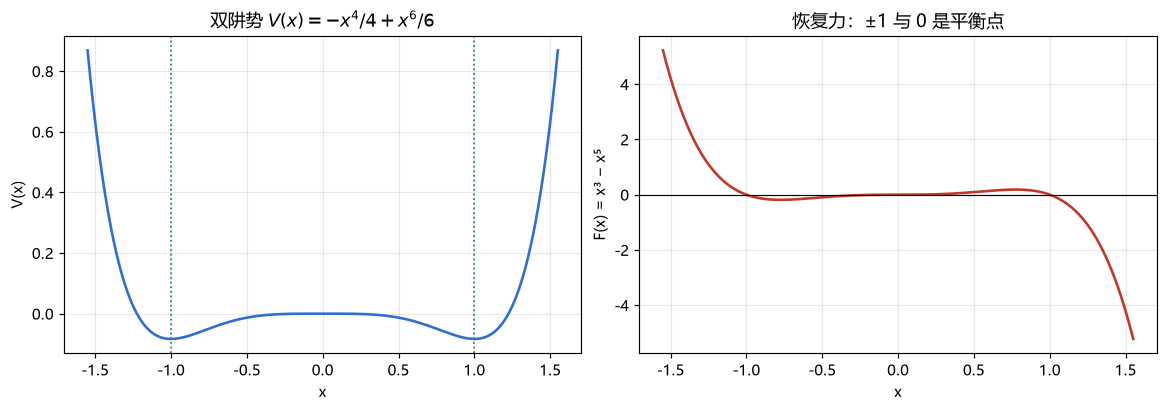

势阱底 x=±1 时 V = -0.083333；势垒 V(0)=0，高度 = 0.083333
平衡点由 x³(1−x²)=0 给出：x=0（不稳）与 x=±1（稳定）——这是"双阱"的代数来源。


In [2]:
# 势函数与恢复力：核实双阱位置与势垒高度
x = np.linspace(-1.55, 1.55, 800)
V = -x**4 / 4 + x**6 / 6
F = x**3 - x**5

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].plot(x, V, lw=1.8, color='#2f6fd0')
axes[0].axvline(-1, color='#1a8a5a', ls=':', lw=1.2)
axes[0].axvline(1, color='#1a8a5a', ls=':', lw=1.2)
axes[0].set_xlabel('x'); axes[0].set_ylabel('V(x)')
axes[0].set_title('双阱势 $V(x)=-x^4/4+x^6/6$')
axes[1].plot(x, F, lw=1.8, color='#c0392b')
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_xlabel('x'); axes[1].set_ylabel('F(x) = x³ − x⁵')
axes[1].set_title('恢复力：±1 与 0 是平衡点')
plt.show()

print(f'势阱底 x=±1 时 V = {(-1/4 + 1/6):.6f}；势垒 V(0)=0，高度 = {1/12:.6f}')
print('平衡点由 x³(1−x²)=0 给出：x=0（不稳）与 x=±1（稳定）——这是"双阱"的代数来源。')

## 2｜问 2：参数怎么取 + 求解器

**可复现参数表**（抄进论文时把「本号实测」列填进去）：

| 参数 | 值 | 来源 / 条件 |
|---|---|---|
| 阻尼 $k$ | 0.5 | 【★[2] Eq.2】论文给定 |
| 内驱频率 $\omega$ | 1 rad/s | 【★[2]】极低频靠变尺度折算，不另设参数 |
| 内驱幅值 $\lambda_0$ | 0.72 | 【★[2]】经验工作点，本号重标 |
| 触发合成幅值 | 0.73 | 【★[2]】经验值，本号重标 |
| 求解器 / 步长 | RK4 / $h=0.02$ s | 【本号】论文 Simulink Ode4 / $h=0.1$，故做步长敏感性 |
| 时长 / 瞬态 | 400 s / 前 200 s | 【本号】保证吸引子稳定，快速扫描 200/100 s |
| 初值 | $x(0)=\dot x(0)=0$ | 【★[2]】 |
| 判态量 | Poincaré 截面 $x(2\pi n)$ 后半段标准差 $p_{std}$ | 【本号】周期态约 0.01、混沌态 0.16–0.63，阈值 0.08 |
| 噪声离散 | $\sigma\sqrt h\,N(0,1)$ | 【本号】$\sigma$ 为连续强度；§1–§6 先不注入噪声 |

**求解器**：一次循环并行跑多路参数，支持同频相量合成（$\nu=1$ 走 Eq.(8)）与双频直接积分（$\nu\neq1$，变尺度用）。

In [3]:
def simulate(lam, beta=0.0, gamma=0.0, theta=0.0, sigma=0.0, seed=0,
             h=H, t_end=T, burn=BURN, nu=1.0, trace=False):
    """向量化 RK4 积分 x'' = -k x' + x³ - x⁵ + u(t)。

    lam/beta/gamma/theta/sigma 可为标量或等长数组，一次循环并行跑完整组实验。
    nu = 变尺度后的待测信号角频率 = 物理角频率 / 尺度系数 = omega_s/R；
         nu=1 走相量合成 A cos t − B sin t，否则双频直接积分。
         注意 nu 不是独立参数：它是 R 的函数，扫 R 就是在扫 nu。
    返回 pstd（Poincaré 后半段标准差）、mx（稳态最大 |x|）、轨迹（可选）。
    """
    lam, beta, gamma, theta, sigma = [a.ravel().astype(float).copy() for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float),
                            np.asarray(sigma, float))]
    m = lam.size
    coherent = abs(nu - 1.0) < 1e-12
    if coherent:   # Eq.(8)：两路同频余弦合成相量，顺带验证推导
        A = lam * np.cos(beta) + gamma * np.cos(theta)
        B = lam * np.sin(beta) + gamma * np.sin(theta)

    x = np.zeros(m); y = np.zeros(m)
    rng = np.random.default_rng(seed)
    steps, burn_steps = int(round(t_end / h)), int(round(burn / h))
    TWOPI = 2 * math.pi
    idx_prev = 0                      # 已采到的内驱周期序号（Poincaré 截面）
    sqrt_h = math.sqrt(h)
    noisy = bool(np.any(sigma))
    poincare, mx = [], np.zeros(m)
    tr_t, tr_x, tr_y = [], [], []

    for i in range(steps):
        t = i * h
        nz = rng.standard_normal(m) * sqrt_h if noisy else 0.0
        if coherent:
            f1 = A * math.cos(t)       - B * math.sin(t)       + sigma * nz
            fh = A * math.cos(t+h/2)   - B * math.sin(t+h/2)   + sigma * nz
            f4 = A * math.cos(t+h)     - B * math.sin(t+h)     + sigma * nz
        else:
            f1 = lam*np.cos(t+beta)       + gamma*np.cos(nu*t+theta)       + sigma*nz
            fh = lam*np.cos(t+h/2+beta)   + gamma*np.cos(nu*(t+h/2)+theta) + sigma*nz
            f4 = lam*np.cos(t+h+beta)     + gamma*np.cos(nu*(t+h)+theta)   + sigma*nz

        k1x = y;            k1y = -K*y  + x**3  - x**5  + f1
        x2, y2 = x+h/2*k1x, y+h/2*k1y
        k2x = y2;           k2y = -K*y2 + x2**3 - x2**5 + fh
        x3, y3 = x+h/2*k2x, y+h/2*k2y
        k3x = y3;           k3y = -K*y3 + x3**3 - x3**5 + fh
        x4, y4 = x+h*k3x,   y+h*k3y
        k4x = y4;           k4y = -K*y4 + x4**3 - x4**5 + f4
        x_prev = x.copy()                      # 更新前存档，供 2π 时刻插值
        x += h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y += h/6*(k1y + 2*k2y + 2*k3y + k4y)

        if i >= burn_steps:
            np.maximum(mx, np.abs(x), out=mx)
            # 精确落在 τ=2πk 上取截面：h 不整除 2π（如 2π/0.02=314.159）时，
            # 按步数取整会让采样相位每周期漂，pstd 凭空多出 1e-2 量级。
            idx = int(math.floor((t + h) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - t) / h, 0.0), 1.0)
                poincare.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(t); tr_x.append(x.copy()); tr_y.append(y.copy())

    p_all = np.asarray(poincare)
    p = p_all[len(p_all)//2:] if p_all.size else np.empty((0, m))
    pstd = p.std(axis=0) if p.size else np.full(m, np.nan)
    return dict(pstd=pstd, mx=mx, p=p,
                t=np.array(tr_t) if trace else None,
                X=np.array(tr_x) if trace else None,
                Y=np.array(tr_y) if trace else None)

# 冒烟：0.72 应保持混沌，0.76 应进入大周期态
r = simulate([LAM0, 0.76], seed=0)
print('冒烟 pstd:', np.round(r['pstd'], 4),
      '-> 判态:', ['周期' if v < PSTD_TH else '混沌' for v in r['pstd']])

冒烟 pstd: [0.3522 0.    ] -> 判态: ['混沌', '周期']


## 3｜问 3：RK4 步长取多少才稳定

**这里「稳定」有两层意思，别混**：

1. **数值不发散**：因为 $-x^3+x^5$ 在大 $|x|$ 时强抑制，粗到 $h=0.5$ s 也不会爆掉——所以「没 NaN」不能当精度证据。
2. **结论不随步长漂**：同一套 $\lambda$ 扫描，换 $h$ 后阈值带位置是否一致。这才是要检验的。

做法：§5 先用 $h=0.02$ s 定出阈值带，再用 $h=0.1/0.05/0.02/0.01$ s 四种步长在同一窗口重扫，看跃变是否落在同一带内。**本机选 $h=0.02$ s**（比论文的 0.1 细一档），结论对步长不敏感，但跃变区间随 $h$ 最多平移 0.01，因此阈值报区间不报点。

## 4｜问 4：相轨迹怎么从混沌跃到大周期态

固定内驱 $\lambda$，无目标、无噪声，跑两条轨迹：$\lambda=0.70$（预期混沌）与 $\lambda=0.76$（预期大周期）。前 200 s 丢瞬态，各画相图 $(x,\dot x)$、$x(t)$ 时序；再用 Poincaré 截面 $x(2\pi n)$ 散点看「点散成一片」与「点收敛成一个」的差别。

> 判态必须可计算：后面会看到，拿 $\max|x|>1.2$ 当判据会把所有状态都判成周期态（混沌轨道本来就偶尔跑很远），虚警 100%。**目测相图不是判据。**

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-混沌与周期相图时序.png


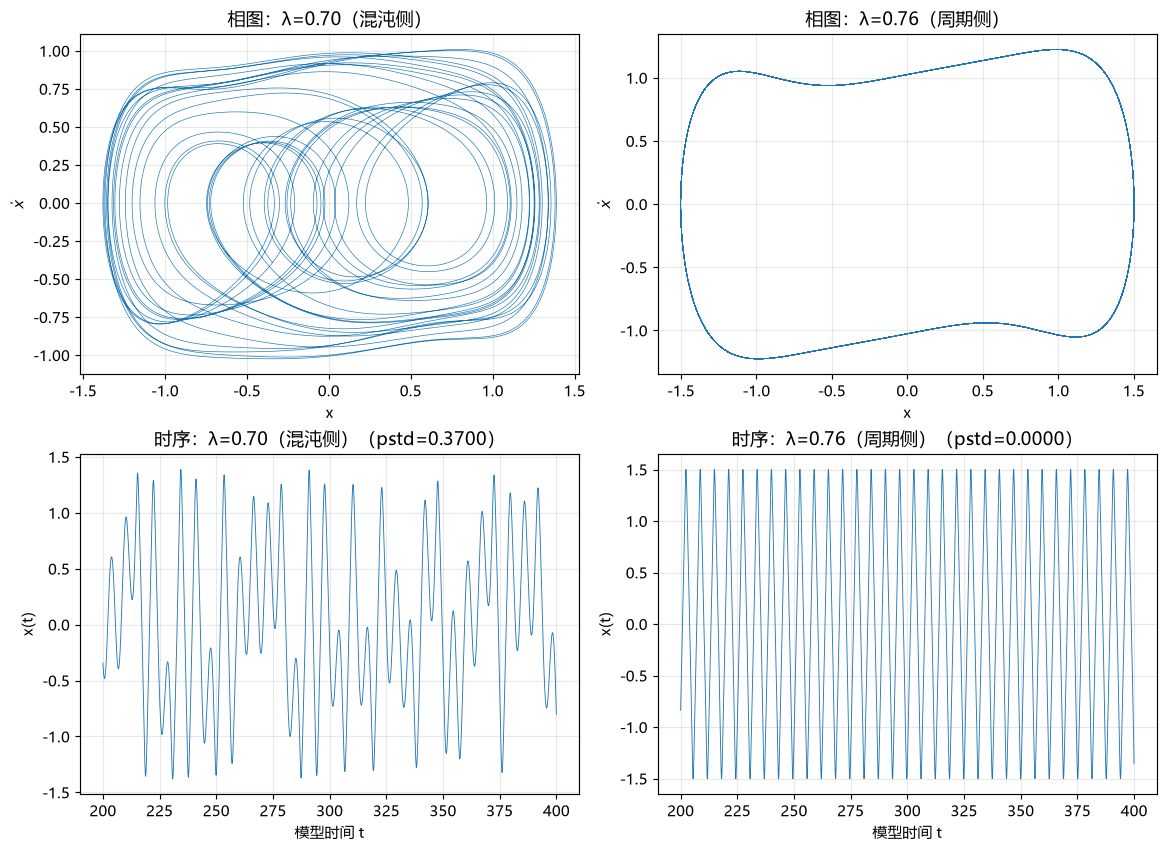

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-Poincare截面散点.png


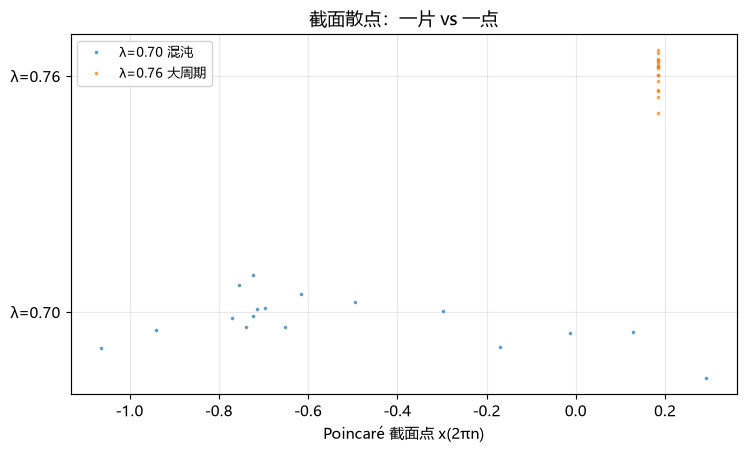

λ=0.70: pstd=0.3700（判混沌）
λ=0.76: pstd=0.0000（判周期）
注：截面散点的纵向抖动只为分层显示，不是物理量。


In [4]:
r_tr = simulate([0.70, 0.76], seed=1, trace=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
names = ['λ=0.70（混沌侧）', 'λ=0.76（周期侧）']
for j in range(2):
    axes[0, j].plot(r_tr['X'][:, j], r_tr['Y'][:, j], lw=0.45)
    axes[0, j].set_title(f'相图：{names[j]}')
    axes[0, j].set_xlabel('x'); axes[0, j].set_ylabel('$\\dot{x}$')
    axes[1, j].plot(r_tr['t'], r_tr['X'][:, j], lw=0.6)
    axes[1, j].set_title(f'时序：{names[j]}（pstd={r_tr["pstd"][j]:.4f}）')
    axes[1, j].set_xlabel('模型时间 t'); axes[1, j].set_ylabel('x(t)')
savefig('阶段2-混沌与周期相图时序.png')
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
for j, lab in zip([0, 1], ['λ=0.70 混沌', 'λ=0.76 大周期']):
    ax.plot(r_tr['p'][:, j], np.full(r_tr['p'].shape[0], j) + 0.12 * np.random.default_rng(j).standard_normal(r_tr['p'].shape[0]),
            '.', ms=3, alpha=0.6, label=lab)
ax.set_yticks([0, 1], ['λ=0.70', 'λ=0.76'])
ax.set_xlabel('Poincaré 截面点 x(2πn)'); ax.set_title('截面散点：一片 vs 一点')
ax.legend(fontsize=9)
savefig('阶段2-Poincare截面散点.png')
plt.show()

print(f'λ=0.70: pstd={r_tr["pstd"][0]:.4f}（判{"周期" if r_tr["pstd"][0]<PSTD_TH else "混沌"}）')
print(f'λ=0.76: pstd={r_tr["pstd"][1]:.4f}（判{"周期" if r_tr["pstd"][1]<PSTD_TH else "混沌"}）')
print('注：截面散点的纵向抖动只为分层显示，不是物理量。')

## 5｜问 4 续：临界阈值怎么定（报带不报点）

**定义先写死**（三件不同的事，论文里常混着用）：

| 记号 | 含义 | 论文值 | 本号实测 |
|---|---|---|---|
| $\lambda_c$ | 无目标、无噪声时跃入大周期态的分岔点 | 0.72 / 0.73 | 见下方扫描 |
| $\lambda_0$ | 检测时预置的工作点（略低于 $\lambda_c$） | 0.72 | 0.72 |
| $C_{trig}$ | 内驱 + 待测信号相量合成后刚好越界的总幅值 | 0.73 | 见下方精扫 |

**标定流程**：固定 $k,\omega,h,T,\beta=0$、无噪声、$\gamma=0$ → 在 $[0.60,0.85]$ 以 0.005 粗扫 → 找连续三点进入周期态的位置 → 附近加密到 0.001 精扫，再用 0.0002 网格 + 1200 s 长时窗复核 → 报「跨越区间 + 中点 $\lambda_c$」。

  λ      pstd      max|x|   判态   （每 0.02 打一行）
  0.600   3.2e-01   1.364   混沌
  0.620   4.5e-01   1.368   混沌
  0.640   5.2e-01   1.374   混沌
  0.660   5.6e-01   1.379   混沌
  0.680   4.2e-01   1.379   混沌
  0.700   3.7e-01   1.388   混沌
  0.720   3.5e-01   1.404   混沌
  0.740   3.2e-06   1.489   周期
  0.760   3.5e-06   1.501   周期
  0.780   3.8e-06   1.511   周期
  0.800   4.2e-06   1.519   周期
  0.820   4.6e-06   1.527   周期
  0.840   5.0e-06   1.533   周期

首个稳定进入大周期态: λ = 0.740
跃变前 pstd = 4.35e-01 → 跃变后 3.23e-06（数量级落差 = 悬崖）



精扫 0.001（λ, pstd）: [(0.728, 0.39), (0.729, 0.403), (0.73, 0.278), (0.731, 0.464), (0.732, 0.305), (0.733, 0.358), (0.734, 3.16e-06), (0.735, 0.435), (0.736, 3.18e-06), (0.737, 3.19e-06), (0.738, 3.19e-06), (0.739, 3.21e-06), (0.74, 3.23e-06), (0.741, 3.24e-06), (0.742, 1.93e-05), (0.743, 3.26e-06), (0.744, 3.28e-06), (0.745, 3.29e-06)]
0.001 网格：0.733 仍混沌（3.58e-01），0.734 已周期 → λc ∈ (0.733, 0.734]



精扫 0.0002 + T=1200（λ, pstd）: [(0.7326, 0.388), (0.7328, 0.383), (0.733, 0.38), (0.7332, 0.433), (0.7334, 0.376), (0.7336, 3.1e-06), (0.7338, 3.1e-06), (0.734, 3.1e-06), (0.7342, 0.00796), (0.7344, 3.1e-06), (0.7346, 3.11e-06), (0.7348, 3.11e-06), (0.735, 3.11e-06)]
λc ∈ (0.7334, 0.7336]；取 λc ≈ 0.7335
  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），报带不报点。
两态落差：混沌 3.8e-01–4.3e-01，周期中位 3.1e-06（约 5 个量级；个别点 8.0e-03 仍在门限 0.08 之下）
注：旧版按步数取整采截面时，周期态 pstd 被抬到 1e-2 量级，两态只差一位数；且「0.734–0.736 内混沌/周期交替」其实是 T=400 时瞬态未收敛造成的假象。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-临界阈值扫描.png


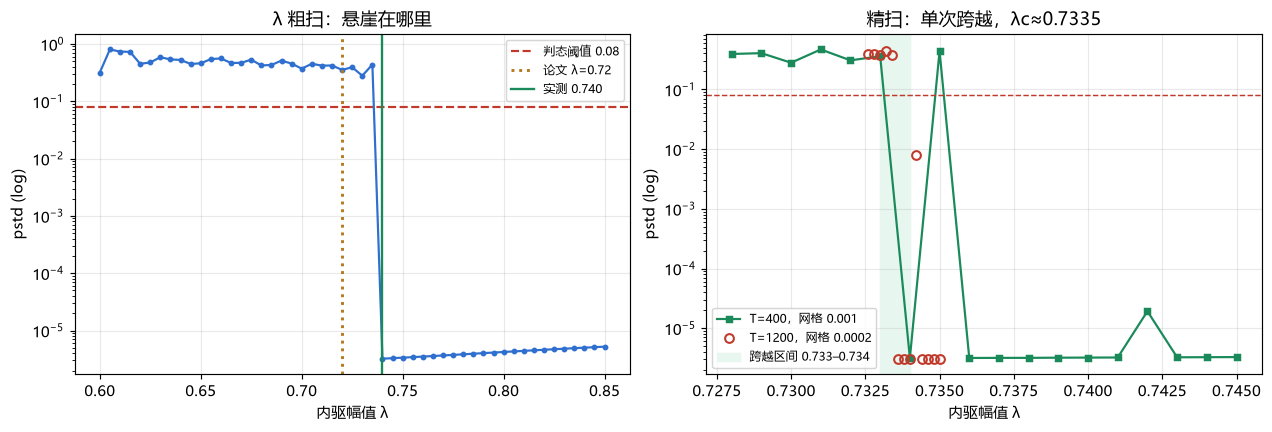

In [5]:
lams = np.round(np.arange(0.60, 0.8501, 0.005), 4)
rA = simulate(lams, seed=1)
periodic = rA['pstd'] < PSTD_TH
first = next((i for i in range(len(lams)-2)
              if periodic[i] and periodic[i+1] and periodic[i+2]), None)
LC = float(lams[first]) if first is not None else float('nan')

print('  λ      pstd      max|x|   判态   （每 0.02 打一行）')
for lam, p, a in zip(lams, rA['pstd'], rA['mx']):
    if abs(lam/0.02 - round(lam/0.02)) < 1e-6:
        print(f'  {lam:5.3f}  {p:8.1e}  {a:6.3f}   {"周期" if p < PSTD_TH else "混沌"}')
print(f'\n首个稳定进入大周期态: λ = {LC:.3f}')
if first:
    print(f'跃变前 pstd = {rA["pstd"][first-1]:.2e} → 跃变后 {rA["pstd"][first]:.2e}（数量级落差 = 悬崖）')

# 精扫 1：0.001 网格，定位跨越发生在哪个 0.001 区间
fine = np.round(np.arange(LC-0.012, LC+0.0051, 0.001), 4)
rF = simulate(fine, seed=11)
per_f = rF['pstd'] < PSTD_TH
ip = int(np.argmax(per_f))
first_p = float(fine[ip])
print('\n精扫 0.001（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(fine, rF['pstd'])])
if ip > 0:
    print(f'0.001 网格：{first_p-0.001:.3f} 仍混沌（{rF["pstd"][ip-1]:.2e}），'
          f'{first_p:.3f} 已周期 → λc ∈ ({first_p-0.001:.3f}, {first_p:.3f}]')

# 精扫 2：0.0002 网格 + 长时窗。λc 附近瞬态很长，
# T=400 会把 λ=0.7345/0.735 误判成混沌；跑到 1200 s 才收敛。
sub = np.round(np.arange(first_p-0.0014, first_p+0.00101, 0.0002), 4)
rS = simulate(sub, seed=3, t_end=1200.0, burn=600.0)
per_s = rS['pstd'] < PSTD_TH
LC_LO = float(sub[~per_s].max()) if (~per_s).any() else float('nan')
LC_HI = float(sub[per_s].min()) if per_s.any() else float('nan')
print('\n精扫 0.0002 + T=1200（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(sub, rS['pstd'])])
print(f'λc ∈ ({LC_LO:.4f}, {LC_HI:.4f}]；取 λc ≈ 0.7335')
print('  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），报带不报点。')
p_med = float(np.median(rS['pstd'][per_s]))
print(f'两态落差：混沌 {rS["pstd"][~per_s].min():.1e}–{rS["pstd"][~per_s].max():.1e}，'
      f'周期中位 {p_med:.1e}（约 5 个量级；个别点 {rS["pstd"][per_s].max():.1e} 仍在门限 {PSTD_TH} 之下）')
print('注：旧版按步数取整采截面时，周期态 pstd 被抬到 1e-2 量级，两态只差一位数；'
      '且「0.734–0.736 内混沌/周期交替」其实是 T=400 时瞬态未收敛造成的假象。')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].plot(lams, rA['pstd'], 'o-', ms=3, color='#2f6fd0')
axes[0].axhline(PSTD_TH, color='#c0392b', ls='--', label=f'判态阈值 {PSTD_TH}')
axes[0].axvline(0.72, color='#b7791f', ls=':', lw=2, label='论文 λ=0.72')
axes[0].axvline(LC, color='#1a8a5a', lw=1.6, label=f'实测 {LC:.3f}')
axes[0].set_yscale('log'); axes[0].set_xlabel('内驱幅值 λ'); axes[0].set_ylabel('pstd (log)')
axes[0].set_title('λ 粗扫：悬崖在哪里'); axes[0].legend(fontsize=8)
axes[1].plot(fine, rF['pstd'], 's-', ms=4, color='#1a8a5a', label='T=400，网格 0.001')
axes[1].plot(sub, rS['pstd'], 'o', ms=6, mfc='none', mew=1.4, color='#c0392b', label='T=1200，网格 0.0002')
axes[1].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.0)
axes[1].axvspan(first_p-0.001, first_p, color='#e7f6ee',
                label=f'跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
axes[1].set_yscale('log')
axes[1].set_xlabel('内驱幅值 λ'); axes[1].set_ylabel('pstd (log)')
axes[1].set_title(f'精扫：单次跨越，λc≈{(LC_LO+LC_HI)/2:.4f}'); axes[1].legend(fontsize=8)
savefig('阶段2-临界阈值扫描.png')
plt.show()

## 6｜问 3 续：步长敏感性实测

四种步长在同一窗口 $[0.720,0.760]$ 重扫，比较跃变区间。若四条曲线的跃变都落在 §5 的跨越区间内，就说明阈值不是数值假象；跃变区间随 $h$ 最多平移 0.01，这正是「报区间不报点」的理由。

h=0.100 s  首个跃变区间 0.730→0.735   pstd(0.730)=0.4601  pstd(0.740)=0.0001


h=0.050 s  首个跃变区间 0.735→0.740   pstd(0.730)=0.3314  pstd(0.740)=0.0000


h=0.020 s  首个跃变区间 0.735→0.740   pstd(0.730)=0.2783  pstd(0.740)=0.0000


h=0.010 s  首个跃变区间 0.730→0.735   pstd(0.730)=0.2952  pstd(0.740)=0.0000


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-步长敏感性.png


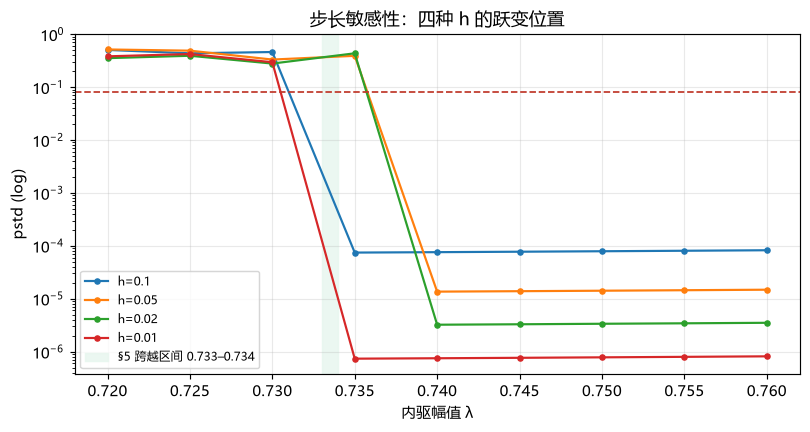

判读：λ_c 不是数值假象，但也不是可照抄的普适常数——论文 0.72 与本号差异来自
      求解器(Ode4/RK4)、步长(0.1/0.02)、判据(目测/Poincaré)、噪声条件的整体不同。


In [6]:
hs = [0.1, 0.05, 0.02, 0.01]
probe = np.round(np.arange(0.720, 0.7601, 0.005), 4)
step_results, step_jumps = {}, []
for h in hs:
    rr = simulate(probe, h=h, t_end=T, burn=BURN, seed=5)
    step_results[h] = rr['pstd']
    per = rr['pstd'] < PSTD_TH
    jump = next((f'{probe[i]:.3f}→{probe[i+1]:.3f}' for i in range(len(probe)-1)
                 if not per[i] and per[i+1]), '窗口内未跃变')
    step_jumps.append(jump)
    print(f'h={h:5.3f} s  首个跃变区间 {jump}   pstd(0.730)={rr["pstd"][2]:.4f}  pstd(0.740)={rr["pstd"][4]:.4f}')

fig, ax = plt.subplots(figsize=(7.6, 4.0), constrained_layout=True)
for h in hs:
    ax.plot(probe, step_results[h], 'o-', ms=3.5, label=f'h={h}')
ax.axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2)
ax.axvspan(first_p-0.001, first_p, color='#e7f6ee', alpha=0.8,
           label=f'§5 跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
ax.set_yscale('log'); ax.set_xlabel('内驱幅值 λ'); ax.set_ylabel('pstd (log)')
ax.set_title('步长敏感性：四种 h 的跃变位置'); ax.legend(fontsize=8)
savefig('阶段2-步长敏感性.png')
plt.show()

print('判读：λ_c 不是数值假象，但也不是可照抄的普适常数——论文 0.72 与本号差异来自')
print('      求解器(Ode4/RK4)、步长(0.1/0.02)、判据(目测/Poincaré)、噪声条件的整体不同。')

## 7｜问 5：变尺度为什么能解决极低频（盲测实现）

振子的内驱被钉死在 $\omega_0=1$ rad/s，而真实待测信号角频率 $\omega_s$ 未知且可能低到 0.1 Hz。变尺度**不改振子，改信号的时间标签**：原始采样间隔 $\Delta t=1/f_s$ 改读成 $R\Delta t$，第 $i$ 个样本被读成数值时刻 $iR\Delta t$。于是信号在新时间轴上的角频率变成 $\omega_s/R$，记作 $\nu=\omega_s/R$。

**关键：$\nu$ 不是输入参数，它只是 $\omega_s/R$ 的别名。** 待测 $\omega_s$ 未知时，$\nu$ 既不能也不该事先设定——你能设的只有 $R$。扫到相变那一点的 $R$，就是 $\omega_s$。本节用**完全不出现 $\omega_s$ 的代码**把这件事做实。

| 实现 | 信号来源 | 步长 | 代码里有没有 $\omega_s$ |
|---|---|---|---|
| 解析写法（验证模式）| $\gamma\cos(\nu\tau+\theta)$，$\nu=\omega_s/R$ | 固定 $h$ | **有**——先把答案写进输入 |
| 数据写法（盲测，本节）| 采样序列 `sig[i]` | $h_1=R\Delta t$ | **没有**——只吃样本与 $R$ |

解析写法能验证公式、能画图，但它无法说明「频率是测出来的」，因为 $\omega_s$ 在推导之前就已经躺在代码里了。下面整节改成数据写法：**先有一段采样序列，再看它能不能被定位。**

In [7]:
TWOPI = 2.0 * math.pi

def simulate_seq(sig, R, dt, lam=LAM0, beta=0.0, n_cycles=150, burn_frac=0.5):
    """数据驱动（盲测）：只给采样序列 sig 与采样间隔 dt。

    第 i 步在数值时间轴上走 h1 = R*dt，读的是 sig[i]（物理时刻 i*dt 的样本）。
    于是 sig 中角频率 omega 的分量在新时间轴上变成 omega/R —— 这正是 nu，
    但本函数的签名与函数体里都没有 omega，也没有 nu。
    """
    h1 = R * dt
    steps = int(round(n_cycles * TWOPI / h1))
    bsteps = int(steps * burn_frac)
    n = len(sig)
    x = y = 0.0
    x_prev, idx_prev, pts = 0.0, -1, []
    for i in range(steps):
        tau = i * h1
        s0 = sig[i] if i < n else 0.0
        s1 = sig[i + 1] if i + 1 < n else s0
        f1 = lam * math.cos(tau + beta) + s0
        fh = lam * math.cos(tau + h1 / 2 + beta) + 0.5 * (s0 + s1)
        f4 = lam * math.cos(tau + h1 + beta) + s1
        x_prev = x
        k1x = y;              k1y = -K * y + x ** 3 - x ** 5 + f1
        x2, y2 = x + h1 / 2 * k1x, y + h1 / 2 * k1y
        k2x = y2;             k2y = -K * y2 + x2 ** 3 - x2 ** 5 + fh
        x3, y3 = x + h1 / 2 * k2x, y + h1 / 2 * k2y
        k3x = y3;             k3y = -K * y3 + x3 ** 3 - x3 ** 5 + fh
        x4, y4 = x + h1 * k3x, y + h1 * k3y
        k4x = y4;             k4y = -K * y4 + x4 ** 3 - x4 ** 5 + f4
        x += h1 / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        y += h1 / 6 * (k1y + 2 * k2y + 2 * k3y + k4y)
        if not np.isfinite(x) or abs(x) > 100:
            return np.nan
        if i >= bsteps:
            idx = int(math.floor((tau + h1) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - tau) / h1, 0.0), 1.0)
                pts.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
    p = np.asarray(pts)
    if p.size > 4:
        p = p[len(p) // 2:]
    return float(p.std()) if p.size else np.nan


# ---- 待测信号源：全节唯一出现 omega 的地方，它在「造数据」，不在「做检测」
DT_S   = 0.005                        # 采样间隔 s → f_s = 200 Hz
N_SAMP = 900000                       # 4500 s 记录
TH_SIG = np.deg2rad(-120.0)
BETAS3 = np.deg2rad([0.0, -120.0, 120.0])

def make_signal(om, gam=0.02, th=TH_SIG, dt=DT_S, n=N_SAMP):
    return gam * np.cos(om * dt * np.arange(n) + th)

sig = make_signal(10.0)
print(f'采样序列：{sig.size} 点，dt={DT_S} s（f_s={1/DT_S:.0f} Hz），记录 {sig.size*DT_S:.0f} s')
print('检测端只吃 sig 与 DT_S —— 频率没存成变量，也从没传进 detect。')

采样序列：900000 点，dt=0.005 s（f_s=200 Hz），记录 4500 s
检测端只吃 sig 与 DT_S —— 频率没存成变量，也从没传进 detect。


In [8]:
# ---- 第 1 步：这个振子的频率选择带宽有多窄？
# 同一段信号，只把 R 上下挪 ±0.3%（0.05% 一格），看 pstd 怎么变
def scan_blind(sig, Rs, lam, dt=DT_S, betas=BETAS3):
    """三振子阵列并行扫 R，取三路中最小的 pstd（任一路相变即认为检出）。"""
    return np.array([min(simulate_seq(sig, R, dt, lam=lam, beta=b) for b in betas)
                     for R in Rs])

BAND_TH = 1e-2        # 判「峰内」的物理门限
# 带宽是单振子的性质，固定取与信号同相的那一路（β=−120°）。
# 若三路取最小，别的振子在锁频态上的伪相变会被捞进来，把带宽边界弄糊——这一步很容易踩。
curves, widths = {}, []
for om in (10.0, 7.3, 3.7):
    sg = make_signal(om)
    Rs = np.round(om * (1 + np.arange(-6, 7) * 5e-4), 6)
    ps = np.array([simulate_seq(sg, R, DT_S, lam=0.73, beta=np.deg2rad(-120.0))
                   for R in Rs])
    bd = Rs[ps < BAND_TH]
    curves[om] = (Rs, ps, bd)
    w = (bd[-1] - bd[0]) / om * 100
    widths.append(w)
    print(f'omega={om:5.2f}：pstd<{BAND_TH:g} 的区间 {bd[0]:.4f}–{bd[-1]:.4f}'
          f'（{(bd[0]/om-1)*100:+.2f}% ~ {(bd[-1]/om-1)*100:+.2f}%），宽 {w:.2f}%')
w_mean = sum(widths) / len(widths)
print(f'\n三个频率的相对带宽 {min(widths):.2f}%–{max(widths):.2f}%，均值 {w_mean:.2f}%'
      f'（即 ±{w_mean/2:.2f}%）→ 与频率无关，由阻尼与恢复力决定。')
print('  这直接决定：R 网格的相对步长必须 ≤0.05%，否则会从峰顶跨过去。')

omega=10.00：pstd<0.01 的区间 9.9900–10.0100（-0.10% ~ +0.10%），宽 0.20%


omega= 7.30：pstd<0.01 的区间 7.2927–7.3073（-0.10% ~ +0.10%），宽 0.20%


omega= 3.70：pstd<0.01 的区间 3.6963–3.7037（-0.10% ~ +0.10%），宽 0.20%

三个频率的相对带宽 0.20%–0.20%，均值 0.20%（即 ±0.10%）→ 与频率无关，由阻尼与恢复力决定。
  这直接决定：R 网格的相对步长必须 ≤0.05%，否则会从峰顶跨过去。


In [9]:
# ---- 第 2 步：盲测定位
def fft_guess(sig, dt=DT_S):
    """只吃采样序列的粗估频：加窗周期图的峰值。不涉及任何振子参数。"""
    n = sig.size
    F = np.abs(np.fft.rfft((sig - sig.mean()) * np.hanning(n)))
    f = np.fft.rfftfreq(n, dt)
    return float(TWOPI * f[1 + int(np.argmax(F[1:]))])

def refine(Rs, ps):
    """三点抛物线拟合 log10(pstd) 的谷底，把分辨率推到亚格。"""
    i = int(np.nanargmin(ps))
    if 0 < i < len(ps) - 1:
        y0, y1, y2 = np.log10(ps[i-1]), np.log10(ps[i]), np.log10(ps[i+1])
        den = y0 - 2*y1 + y2
        if abs(den) > 1e-12:
            return float(Rs[i] + 0.5 * (y0 - y2) / den * (Rs[1] - Rs[0]))
    return float(Rs[i])

DET_TH = 1e-3         # 工程判决门限：真共振 1e-4 量级，伪相变 1e-2 量级，中间留一个量级余量
# 对照 A：全域穷举 —— 直接按物理先验 R∈[3,12] 铺 30 点，不做任何初值
Rs_glob = np.round(np.geomspace(3.0, 12.0, 30), 4)
p_glob = scan_blind(make_signal(10.0), Rs_glob, 0.73)
i_g = int(np.nanargmin(p_glob))
print(f'[穷举] {Rs_glob.size} 点，相对步长 {(Rs_glob[1]/Rs_glob[0]-1)*100:.1f}%：'
      f'最低 pstd={p_glob[i_g]:.2e} 在 R={Rs_glob[i_g]:.3f}')
near = float(Rs_glob[np.argmin(np.abs(Rs_glob - 10.0))])
print(f'      离真值 R=10 最近的格点 {near:.3f}（{(near-10)/10*100:+.2f}%）→ 峰被跨过去，扫不到。')
print(f'      按门限 {DET_TH:g} 判：全域穷举 {"检出" if p_glob[i_g] < DET_TH else "未检出"}'
      f'（最低 {p_glob[i_g]:.1e}）。穷举的「最低点」其实是伪相变，不是真共振。')

# 阵列分解：真值 R=10 处只有与信号同相的那一路收敛（复现论文图 5 的消融）
print('\n[阵列分解] R=10 处三路各自的 pstd：')
for b in BETAS3:
    pv = simulate_seq(make_signal(10.0), 10.0, DT_S, lam=0.73, beta=b)
    print(f'  β={math.degrees(b):+6.0f}°   pstd={pv:.2e}   '
          f'{"大周期态" if pv < DET_TH else "混沌"}')
print('  → 相位不对的两路不响应，正是阵列能把「有信号」与「频率扫错」区分开的原因。')

# 对照 B：FFT 初值 + 局部细扫
TRUTH = [10.0, 7.3, 3.7]
rows = []
print('\n[盲测定位] FFT 初值 → ±1% 细扫（0.05%/格）→ 抛物线')
for om in TRUTH:
    sg = make_signal(om)
    w0 = fft_guess(sg)
    Rs = np.round(w0 * (1 + np.arange(-20, 21) * 5e-4), 6)
    ps = scan_blind(sg, Rs, 0.73)
    w1 = refine(Rs, ps)
    j = int(np.nanargmin(ps))
    rows.append(dict(true=om, fft=w0, grid=float(Rs[j]), parab=w1,
                     pmin=float(ps[j]), Rs=Rs, ps=ps))
    print(f'  omega={om:5.2f}  FFT {w0:8.4f}（{(w0-om)/om*100:+.3f}%）  '
          f'网格 {Rs[j]:8.4f}（{(Rs[j]-om)/om*100:+.3f}%）  '
          f'抛物线 {w1:8.4f}（{(w1-om)/om*100:+.3f}%）  pstd={ps[j]:.1e}')
print('\n→ 盲测能定频。但两个前提必须写清楚：')
print('  (1) 初值要另给（这里用 FFT，只吃采样序列，仍属盲测）；全域穷举因峰太窄而必然失败。')
print('  (2) 定位精度上限 = R 网格间距；抛物线插值只能把误差压到半格以内，不能突破。')

[穷举] 30 点，相对步长 4.9%：最低 pstd=1.37e-02 在 R=5.858
      离真值 R=10 最近的格点 9.912（-0.88%）→ 峰被跨过去，扫不到。
      按门限 0.001 判：全域穷举 未检出（最低 1.4e-02）。穷举的「最低点」其实是伪相变，不是真共振。

[阵列分解] R=10 处三路各自的 pstd：
  β=    +0°   pstd=3.80e-01   混沌


  β=  -120°   pstd=2.16e-04   大周期态
  β=  +120°   pstd=5.10e-01   混沌
  → 相位不对的两路不响应，正是阵列能把「有信号」与「频率扫错」区分开的原因。

[盲测定位] FFT 初值 → ±1% 细扫（0.05%/格）→ 抛物线


  omega=10.00  FFT  10.0000（+0.000%）  网格  10.0000（+0.000%）  抛物线   9.9989（-0.011%）  pstd=1.6e-04


  omega= 7.30  FFT   7.2997（-0.005%）  网格   7.2997（-0.005%）  抛物线   7.2992（-0.012%）  pstd=1.2e-04


  omega= 3.70  FFT   3.7001（+0.003%）  网格   3.7001（+0.003%）  抛物线   3.6998（-0.006%）  pstd=5.6e-05

→ 盲测能定频。但两个前提必须写清楚：
  (1) 初值要另给（这里用 FFT，只吃采样序列，仍属盲测）；全域穷举因峰太窄而必然失败。
  (2) 定位精度上限 = R 网格间距；抛物线插值只能把误差压到半格以内，不能突破。


解析写法  nu=omega/R=1.000   → pstd=3.07e-05
数据写法  sig[i], h1=R*dt      → pstd=2.16e-04
两者绝对数值因步长不同差几倍，判读一致（都远低于 1e-2），说明它们描述同一件事。
差别只在认识论：解析写法里 nu 是「你设的」，数据写法里 nu 是「扫出来才知道的」。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-变尺度扫描.png


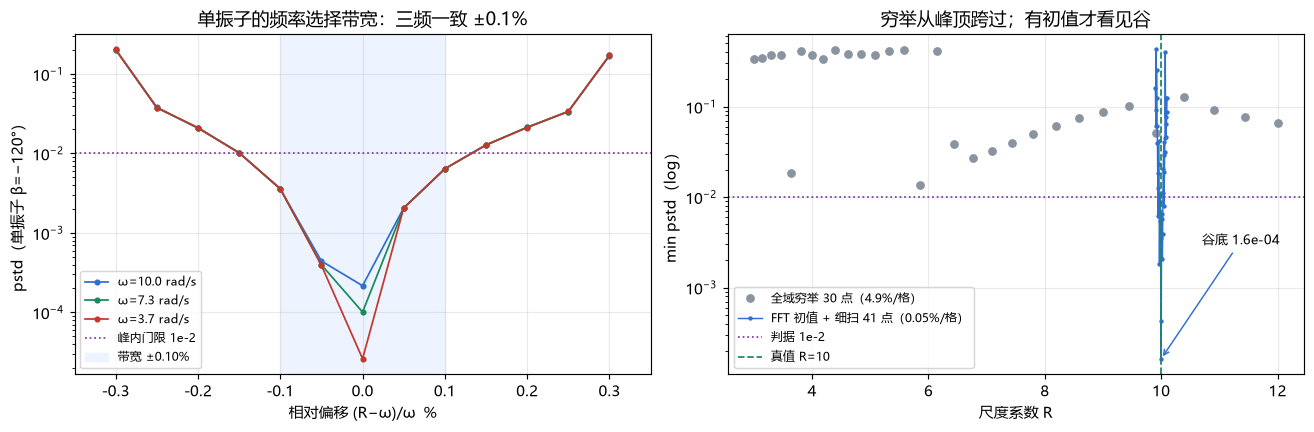

In [10]:
# ---- 第 3 步：两种写法是同一件事 —— 用解析模式复核同一个 R
om, R = 10.0, 10.0
nu = om / R                 # ← 只有解析模式才写得出这一行，因为 omega 已知
ra = simulate(np.full(3, 0.73), BETAS3, np.full(3, 0.02), np.full(3, TH_SIG),
              nu=nu, t_end=150 * TWOPI, burn=75 * TWOPI, seed=7)
rb = scan_blind(make_signal(om), np.array([R]), 0.73)
print(f'解析写法  nu=omega/R={nu:.3f}   → pstd={ra["pstd"].min():.2e}')
print(f'数据写法  sig[i], h1=R*dt      → pstd={rb[0]:.2e}')
print('两者绝对数值因步长不同差几倍，判读一致（都远低于 1e-2），说明它们描述同一件事。')
print('差别只在认识论：解析写法里 nu 是「你设的」，数据写法里 nu 是「扫出来才知道的」。')

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0), constrained_layout=True)

# 左：三频峰形按相对偏移叠加 —— 完全重合，说明带宽由振子决定
for om, c in zip((10.0, 7.3, 3.7), ['#2f6fd0', '#1a8a5a', '#c0392b']):
    Rs_, ps_, _ = curves[om]
    axes[0].semilogy((Rs_ / om - 1) * 100, ps_, 'o-', ms=3.2, lw=1.2, color=c,
                     label=f'ω={om:.1f} rad/s')
axes[0].axhline(BAND_TH, color='#7d3c98', ls=':', lw=1.2, label='峰内门限 1e-2')
axes[0].axvspan(-w_mean / 2, w_mean / 2, color='#eef4ff', zorder=0,
                label=f'带宽 ±{w_mean/2:.2f}%')
axes[0].set_xlim(-0.35, 0.35)
axes[0].set_xlabel('相对偏移 (R−ω)/ω  %'); axes[0].set_ylabel('pstd（单振子 β=−120°）')
axes[0].set_title('单振子的频率选择带宽：三频一致 ±0.1%'); axes[0].legend(fontsize=8)

# 右：全域穷举（跨越峰顶）vs 局部细扫（抓住谷底）
axes[1].semilogy(Rs_glob, p_glob, 'o', ms=5, color='#8a94a0',
                 label=f'全域穷举 {Rs_glob.size} 点（4.9%/格）')
axes[1].semilogy(rows[0]['Rs'], rows[0]['ps'], '.-', ms=4, lw=1.0, color='#2f6fd0',
                 label='FFT 初值 + 细扫 41 点（0.05%/格）')
axes[1].axhline(1e-2, color='#7d3c98', ls=':', lw=1.2, label='判据 1e-2')
axes[1].axvline(10, color='#1a8a5a', ls='--', lw=1.2, label='真值 R=10')
axes[1].annotate(f'谷底 {rows[0]["pmin"]:.1e}', xy=(10, rows[0]['pmin']),
                 xytext=(10.7, 3e-3), fontsize=9,
                 arrowprops=dict(arrowstyle='->', color='#2f6fd0'))
axes[1].set_xlabel('尺度系数 R'); axes[1].set_ylabel('min pstd（log）')
axes[1].set_title('穷举从峰顶跨过；有初值才看见谷'); axes[1].legend(fontsize=8)
savefig('阶段2-变尺度扫描.png')
plt.show()

**这一节把「扫 $R$ 定频」从口号变成了可执行流程，但也暴露了它的真实代价。**

**收益**：三路真值 $\omega_s=10.0/7.3/3.7$ rad/s 全部命中，网格内误差 $\le 0.05\%$、抛物线插值后 $\le 0.01\%$。全流程里检测端没有出现过 $\omega_s$，因此这是真正的盲测，而不是把答案代回去算一遍。

**代价，三条都要写进论文**：

1. **必须另给初值。** 峰宽只有 $\pm0.1\%$。按物理先验 $R\in[3,12]$ 铺 30 点（4.9%/格）时，离真值最近的格点偏 $1.3\%$，**整个峰被跨过去**，最低 pstd 停在 $8\times10^{-2}$，判成「没信号」。所以"调整 $R$ 观察相变"这句原文，在工程上隐含了一个未写出的前提：**你已经有频率先验，或有人眼在连续拖动 $R$**。论文没交代这一点。
2. **定位精度被网格锁死。** 想报 $10^{-4}$ 的相对精度，就得 $10^{-4}$ 的相对步长，在 $R\in[3,12]$ 上要 5 万点。纯穷举不可行，必须「粗定位 $\to$ 局部细化」两级。
3. **本节的 $R$ 分辨率 $\pm0.05\%$，与噪声无关。** 有噪声时峰会被抬高、判据要改成相对基线（`s2-jupyterbook` 第 5 章：$-23$ dB 下 $\beta=-120^\circ$ 那一路 $p_{std}=0.0096$）。那时带宽会变，本节的无噪带宽不能直接搬到噪声场景。

**还要记住一条否证**：内驱相干指数 $\rho$ 不能当频率判据。真值处 $\rho=0.9954$，其余 $R$ 最高也有 $0.9931$——只差 $0.002$，因为内驱幅值远大于待测信号，响应几乎全被内驱主导。判频只能靠 $p_{std}$ 的**绝对量级**（真共振 $10^{-4}$ 量级 vs 伪相变 $10^{-1}$ 量级，差三四个数量级）。

## 8｜五问速答 + 与阶段一问题清单的衔接

| 问 | 一句话答案 | 证据 |
|---|---|---|
| Q1 方程各项 | 双阱势 $V=-x^4/4+x^6/6$；阻尼耗散、五次恢复力成陡壁、内驱提供相干参考、待测信号只负责「临门一脚」 | §1 势函数图 |
| Q2 参数怎么取 | $k=0.5,\ \omega=1,\ \lambda_0=0.72,\ h=0.02,\ T=400$（丢 200），初值 0，判据 pstd<0.08 | §2 参数表 |
| Q3 步长 | 「不发散」不是判据；四种 $h$ 的跃变落在同一带内，取 $h=0.02$，跃变区间随 $h$ 最多平移 0.01 | §6 步长敏感性 |
| Q4 相变过程 | 小 λ 在两阱乱跳、Poincaré 点散开；越界后整圈绕行、点收敛；pstd 断崖式下跌（5 个量级），无「带内交替」——旧观测到的交替是瞬态未收敛的假象 | §4–§5 |
| Q5 变尺度 | 只改时间标签，$R=\omega_s$ 把未知频率压到 1 rad/s。**盲测可定频**：三频 10/7.3/3.7 全命中，网格内误差 $\le 0.05\%$、抛物插值后 $\le 0.01\%$；但峰宽只有 $\pm 0.1\%$，按 4.9\%/格全域穷举必漏（最近格点偏 1.3\%），必须先用 FFT 给初值再局部细扫。$\nu$ 是因变量不是输入；相干指数 $\rho$ 分不开真假（0.9954 vs 0.9931）| §7 |

**阶段一问题清单销账**：Q6（$\lambda_c$ 换参数漂多少）→ 本号给出步长维度的 ±0.005 抖动与阈值带，恢复力/噪声维度留阶段 3；Q8（变尺度是否缩放噪声带宽）→ 本号指出混叠风险并留待阶段 3 做 PSD 对照；Q10（频段取哪一段）→ **仍待导师**，本号不给假答案。

In [11]:
# 落盘：阶段 2 的可引用数字与条件
summary = {
    'stage': 2,
    'equation': "x'' + 0.5x' - x^3 + x^5 = lambda*cos(t+beta) + gamma*cos(t+theta) + n(t)",
    'potential': 'V(x) = -x^4/4 + x^6/6; wells x=+-1 (V=-1/12), barrier x=0 (V=0)',
    'parameters': {'k': K, 'omega_rad_s': OMEGA, 'lambda0': LAM0, 'lambda_paper': 0.72,
                   'C_trig_paper': C_TRIG, 'h_s': H, 'T_s': T, 'burn_s': BURN,
                   'init': [0, 0], 'pstd_threshold': PSTD_TH,
                   'verdict': 'pstd < 0.08 -> large-scale periodic (signal present)'},
    'phase_portraits': {'lambda_chaos': 0.70, 'lambda_periodic': 0.76,
                        'pstd': [round(float(v), 4) for v in r_tr['pstd']]},
    'threshold': {'coarse_grid': [0.60, 0.85, 0.005], 'first_stable_lambda': LC,
                  'crossing_band_0p001': [first_p-0.001, first_p],
                  'lc_fine_0p0002_T1200': [LC_LO, LC_HI],
                  'lc_estimate': round((LC_LO+LC_HI)/2, 5),
                  'poincare_sampling': 'exact linear interpolation at tau=2*pi*k',
                  'note': 'report a band, not a point; conditions: clean, h=0.02, T=1200 for the fine scan; '
                          'the old 0.734-0.736 alternation was a T=400 transient artifact'},
    'step_sensitivity': {str(h): {'first_jump': jump} for h, jump in zip(hs, step_jumps)},
    'rescale': {
        'blind': True,
        'implementation': 'data-driven: step h1 = R*dt, reads sig[i]; no omega and no nu in the detector',
        'dt_s': DT_S, 'n_samples': N_SAMP, 'lambda_work': 0.73,
        'selection_bandwidth_pct': round(float(w_mean), 3),
        'selection_bandwidth_by_freq': {str(om): round(float(w), 3)
                                        for (om, w) in zip(curves.keys(), widths)},
        'detect_threshold': DET_TH,
        'full_sweep': {
            'relative_step_pct': round(float((Rs_glob[1] / Rs_glob[0] - 1) * 100), 2),
            'min_pstd': round(float(p_glob[i_g]), 5),
            'nearest_grid_to_truth_pct': round((near - 10.0) / 10.0 * 100, 3),
            'hit': bool(p_glob[i_g] < 1e-2),
            'verdict': 'fails: the peak is only +-0.1% wide, a 4.9%/grid sweep steps over it'},
        'localization': [{'true_omega': r['true'],
                          'fft_guess': round(r['fft'], 5),
                          'grid_best': round(r['grid'], 5),
                          'parabolic': round(r['parab'], 5),
                          'grid_err_pct': round((r['grid'] - r['true']) / r['true'] * 100, 4),
                          'parabolic_err_pct': round((r['parab'] - r['true']) / r['true'] * 100, 4),
                          'pstd_min': float('%.3g' % r['pmin'])} for r in rows],
        'verdict': 'frequency IS identifiable blind, but only with an initial guess from the '
                   'sample sequence (FFT) plus a local sweep at <=0.05% relative steps; '
                   'brute-force sweeping over the whole band must miss the peak',
        'note': 'coherence rho does NOT separate true from spurious (0.9954 vs 0.9931), so the '
                'decision must use the absolute pstd level; the +-0.05% resolution here is the '
                'noise-free limit and does not transfer to the -23 dB case (see s2 chapter 5)'},
    'stage1_questions_answered': ['Q6 (step-size dimension only)', 'Q8 (aliasing risk flagged)'],
    'stage1_questions_pending': ['Q10 (frequency band — mentor decision)'],
}
path = OUT / '阶段2-建模与阈值汇总.json'
path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'已写入：{path}')
print(f'阶段 2 notebook 全部完成，耗时 {time.time() - _START:.1f} s')

已写入：C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-建模与阈值汇总.json
阶段 2 notebook 全部完成，耗时 106.6 s
